Device: cpu

Preparing randomized samples...
Done.

RUNNING MEMBERSHIP INFERENCE ATTACK

MODEL: FP
Confidence AUC: 0.5033
Loss AUC: 0.5057
Entropy AUC: 0.5027
Attack Accuracy: 48.60%

MODEL: FPM
Confidence AUC: 0.5041
Loss AUC: 0.5059
Entropy AUC: 0.5033
Attack Accuracy: 49.20%

MODEL: FPMANR 0.1
Confidence AUC: 0.4936
Loss AUC: 0.4955
Entropy AUC: 0.4931
Attack Accuracy: 50.05%

MODEL: FPMANR 0.2
Confidence AUC: 0.4947
Loss AUC: 0.4858
Entropy AUC: 0.4927
Attack Accuracy: 49.45%

Generating confidence ROC curves...


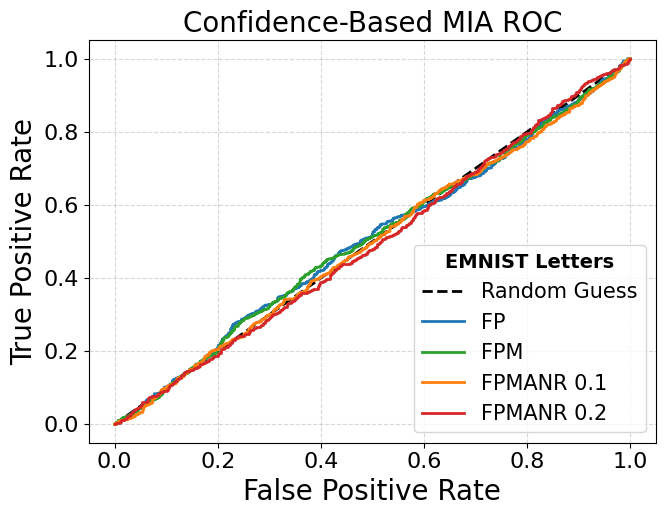

Generating loss ROC curves...


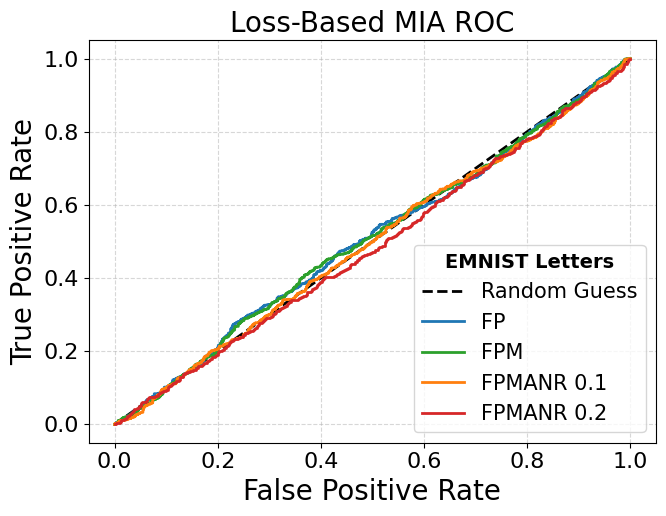

Generating entropy ROC curves...


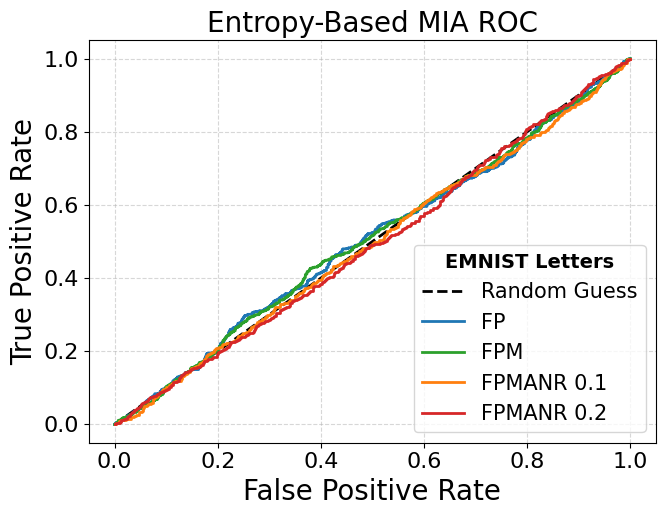


FINAL MEMBERSHIP INFERENCE RESULTS

MODEL: FP
Confidence AUC: 0.5033
Loss AUC: 0.5057
Entropy AUC: 0.5027
Attack Accuracy: 48.60%

MODEL: FPM
Confidence AUC: 0.5041
Loss AUC: 0.5059
Entropy AUC: 0.5033
Attack Accuracy: 49.20%

MODEL: FPMANR 0.1
Confidence AUC: 0.4936
Loss AUC: 0.4955
Entropy AUC: 0.4931
Attack Accuracy: 50.05%

MODEL: FPMANR 0.2
Confidence AUC: 0.4947
Loss AUC: 0.4858
Entropy AUC: 0.4927
Attack Accuracy: 49.45%

MIA EXPERIMENT FINISHED



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done.


In [1]:
# ============================================================
# FULL MEMBERSHIP INFERENCE ATTACK (MIA)
# EMNIST Letters
# IEEE PUBLICATION-READY VERSION
#
# ONLY:
# 1. Written Results
# 2. ROC Curves
#
# Removed:
# - AUC bar graph
# - Attack accuracy graph
# - Histograms
# - Loss distribution graph
#
# Fixes:
# - Larger fonts (+2)
# - Warning suppression
# - Cleaner IEEE figures
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms

import numpy as np
import random
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# ============================================================
# IEEE FONT + FIGURE SETTINGS
# ============================================================

plt.rcParams.update({

    # increased all by +2
    "font.size": 18,

    "axes.labelsize": 20,
    "axes.titlesize": 20,

    "xtick.labelsize": 16,
    "ytick.labelsize": 16,

    "legend.fontsize": 15,

    "figure.titlesize": 20
})

# ============================================================
# SEED + REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# ============================================================
# DATASET
# ============================================================

transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        (0.1307,),
        (0.3081,)
    )
])

# ------------------------------------------------
# TRAIN SET = MEMBERS
# ------------------------------------------------

train_dataset = torchvision.datasets.EMNIST(

    root="./data",
    split="letters",
    train=True,
    download=True,
    transform=transform
)

# ------------------------------------------------
# TEST SET = NON-MEMBERS
# ------------------------------------------------

test_dataset = torchvision.datasets.EMNIST(

    root="./data",
    split="letters",
    train=False,
    download=True,
    transform=transform
)

NUM_CLASSES = 26

# ============================================================
# MODEL
# ============================================================

class EMNIST_CNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.conv1 = nn.Conv2d(
            1,
            32,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            32,
            64,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(2)

        self.fc1 = nn.Linear(
            64 * 7 * 7,
            256
        )

        self.fc2 = nn.Linear(
            256,
            NUM_CLASSES
        )

    def forward(self, x):

        x = self.pool(
            F.relu(self.conv1(x))
        )

        x = self.pool(
            F.relu(self.conv2(x))
        )

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x

# ============================================================
# LOAD MODELS
# ============================================================

def load_model(path):

    model = EMNIST_CNN().to(DEVICE)

    model.load_state_dict(
        torch.load(
            path,
            map_location=DEVICE
        )
    )

    model.eval()

    return model

models = {

    "FP":
        load_model("Baseline_emnist_letters.pth"),

    "FPM":
        load_model("FPMAN_emnist_letters_0.pth"),

    "FPMANR 0.1":
        load_model("FPMAN_emnist_letters_1.pth"),

    "FPMANR 0.2":
        load_model("FPMAN_emnist_letters_2.pth")
}

colors = {
    "FP":  "#1f77b4",  # blue
    "FPM": "#2ca02c",   # green
    "FPMANR 0.1": "#ff7f0e",   # orange
    "FPMANR 0.2": "#d62728"  # red
}

# ============================================================
# MIA SCORE FUNCTION
# ============================================================

def get_mia_scores(model, image, label):

    model.eval()

    with torch.no_grad():

        logits = model(image)

        probs = F.softmax(
            logits,
            dim=1
        )

        # ------------------------------------------------
        # MAX CONFIDENCE
        # ------------------------------------------------

        confidence = probs.max(
            dim=1
        )[0].item()

        # ------------------------------------------------
        # LOSS
        # ------------------------------------------------

        loss = F.cross_entropy(
            logits,
            label
        ).item()

        # ------------------------------------------------
        # ENTROPY
        # ------------------------------------------------

        entropy = -torch.sum(
            probs * torch.log(probs + 1e-12)
        ).item()

    return confidence, loss, entropy

# ============================================================
# RANDOMIZED SAMPLE SELECTION
# ============================================================

NUM_MEMBER_SAMPLES = 1000
NUM_NONMEMBER_SAMPLES = 1000

print("\nPreparing randomized samples...")

member_samples = []
nonmember_samples = []

member_indices = np.random.choice(
    len(train_dataset),
    NUM_MEMBER_SAMPLES,
    replace=False
)

nonmember_indices = np.random.choice(
    len(test_dataset),
    NUM_NONMEMBER_SAMPLES,
    replace=False
)

# ------------------------------------------------
# MEMBER SAMPLES
# ------------------------------------------------

for idx in member_indices:

    img, label = train_dataset[idx]

    member_samples.append((

        img.unsqueeze(0).to(DEVICE),

        torch.tensor([label - 1]).to(DEVICE)
    ))

# ------------------------------------------------
# NON-MEMBER SAMPLES
# ------------------------------------------------

for idx in nonmember_indices:

    img, label = test_dataset[idx]

    nonmember_samples.append((

        img.unsqueeze(0).to(DEVICE),

        torch.tensor([label - 1]).to(DEVICE)
    ))

print("Done.")

# ============================================================
# RUN MEMBERSHIP INFERENCE ATTACK
# ============================================================

mia_results = {}

print("\n================================================")
print("RUNNING MEMBERSHIP INFERENCE ATTACK")
print("================================================")

for model_name, model in models.items():

    print(f"\nMODEL: {model_name}")

    member_confidences = []
    nonmember_confidences = []

    member_losses = []
    nonmember_losses = []

    member_entropies = []
    nonmember_entropies = []

    # ========================================================
    # MEMBER SCORES
    # ========================================================

    for img, label in member_samples:

        conf, loss, entropy = get_mia_scores(
            model,
            img,
            label
        )

        member_confidences.append(conf)
        member_losses.append(loss)
        member_entropies.append(entropy)

    # ========================================================
    # NON-MEMBER SCORES
    # ========================================================

    for img, label in nonmember_samples:

        conf, loss, entropy = get_mia_scores(
            model,
            img,
            label
        )

        nonmember_confidences.append(conf)
        nonmember_losses.append(loss)
        nonmember_entropies.append(entropy)

    # ========================================================
    # TRUE LABELS
    # ========================================================

    y_true = (

        [1] * len(member_confidences)

        +

        [0] * len(nonmember_confidences)
    )

    # ========================================================
    # CONFIDENCE-BASED MIA
    # ========================================================

    confidence_scores = (

        member_confidences

        +

        nonmember_confidences
    )

    confidence_auc = roc_auc_score(
        y_true,
        confidence_scores
    )

    conf_fpr, conf_tpr, _ = roc_curve(
        y_true,
        confidence_scores
    )

    # ========================================================
    # LOSS-BASED MIA
    # ========================================================

    loss_scores = (

        [-x for x in member_losses]

        +

        [-x for x in nonmember_losses]
    )

    loss_auc = roc_auc_score(
        y_true,
        loss_scores
    )

    loss_fpr, loss_tpr, _ = roc_curve(
        y_true,
        loss_scores
    )

    # ========================================================
    # ENTROPY-BASED MIA
    # ========================================================

    entropy_scores = (

        [-x for x in member_entropies]

        +

        [-x for x in nonmember_entropies]
    )

    entropy_auc = roc_auc_score(
        y_true,
        entropy_scores
    )

    entropy_fpr, entropy_tpr, _ = roc_curve(
        y_true,
        entropy_scores
    )

    # ========================================================
    # ATTACK ACCURACY
    # ========================================================

    threshold = np.mean(
        nonmember_confidences
    )

    member_correct = np.sum(
        np.array(member_confidences) > threshold
    )

    nonmember_correct = np.sum(
        np.array(nonmember_confidences) <= threshold
    )

    attack_acc = (

        member_correct + nonmember_correct

    ) / (

        len(member_confidences)

        +

        len(nonmember_confidences)
    )

    # ========================================================
    # SAVE RESULTS
    # ========================================================

    mia_results[model_name] = {

        "confidence_auc":
            confidence_auc,

        "loss_auc":
            loss_auc,

        "entropy_auc":
            entropy_auc,

        "attack_acc":
            attack_acc,

        "conf_fpr":
            conf_fpr,

        "conf_tpr":
            conf_tpr,

        "loss_fpr":
            loss_fpr,

        "loss_tpr":
            loss_tpr,

        "entropy_fpr":
            entropy_fpr,

        "entropy_tpr":
            entropy_tpr
    }

    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print(
        f"Confidence AUC: "
        f"{confidence_auc:.4f}"
    )

    print(
        f"Loss AUC: "
        f"{loss_auc:.4f}"
    )

    print(
        f"Entropy AUC: "
        f"{entropy_auc:.4f}"
    )

    print(
        f"Attack Accuracy: "
        f"{attack_acc * 100:.2f}%"
    )

# ============================================================
# GRAPH 1
# CONFIDENCE ROC CURVE
# ============================================================

print("\nGenerating confidence ROC curves...")

plt.figure(figsize=(7,5.5))

plt.plot(
    [0,1],
    [0,1],
    '--',
    color='black',
    linewidth=2,
    label='Random Guess'
)

for model_name in mia_results:

    plt.plot(

        mia_results[model_name]["conf_fpr"],

        mia_results[model_name]["conf_tpr"],

        linewidth=2,

        color=colors[model_name],

        label=(
            f"{model_name} "
        )
    )

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Confidence-Based MIA ROC")

plt.legend(
    loc="lower right",
    frameon=True,
    title="EMNIST Letters",
    title_fontsize=14
)
plt.setp(plt.gca().get_legend().get_title(), fontweight='bold')

plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig(
    "emnist_letters_confidence_mia_roc.png",
    dpi=1200,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# GRAPH 2
# LOSS ROC CURVE
# ============================================================

print("Generating loss ROC curves...")

plt.figure(figsize=(7,5.5))

plt.plot(
    [0,1],
    [0,1],
    '--',
    color='black',
    linewidth=2,
    label='Random Guess'
)

for model_name in mia_results:

    plt.plot(

        mia_results[model_name]["loss_fpr"],

        mia_results[model_name]["loss_tpr"],

        linewidth=2,

        color=colors[model_name],

        label=(
            f"{model_name} "
        )
    )

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Loss-Based MIA ROC")

plt.legend(
    loc="lower right",
    frameon=True,
    title="EMNIST Letters",
    title_fontsize=14
)
plt.setp(plt.gca().get_legend().get_title(), fontweight='bold')

plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig(
    "emnist_letters_loss_mia_roc.png",
    dpi=1200,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# GRAPH 3
# ENTROPY ROC CURVE
# ============================================================

print("Generating entropy ROC curves...")

plt.figure(figsize=(7,5.5))

plt.plot(
    [0,1],
    [0,1],
    '--',
    color='black',
    linewidth=2,
    label='Random Guess'
)

for model_name in mia_results:

    plt.plot(

        mia_results[model_name]["entropy_fpr"],

        mia_results[model_name]["entropy_tpr"],

        linewidth=2,

        color=colors[model_name],

        label=(
            f"{model_name} "
        )
    )

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Entropy-Based MIA ROC")

plt.legend(
    loc="lower right",
    frameon=True,
    title="EMNIST Letters",
    title_fontsize=14
)
plt.setp(plt.gca().get_legend().get_title(), fontweight='bold')

plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig(
    "emnist_letters_entropy_mia_roc.png",
    dpi=1200,
    bbox_inches='tight'
)

plt.show()

# ============================================================
# FINAL RESULTS
# ============================================================

print("\n================================================")
print("FINAL MEMBERSHIP INFERENCE RESULTS")
print("================================================")

for model_name in mia_results:

    print(f"\nMODEL: {model_name}")

    print(
        f"Confidence AUC: "
        f"{mia_results[model_name]['confidence_auc']:.4f}"
    )

    print(
        f"Loss AUC: "
        f"{mia_results[model_name]['loss_auc']:.4f}"
    )

    print(
        f"Entropy AUC: "
        f"{mia_results[model_name]['entropy_auc']:.4f}"
    )

    print(
        f"Attack Accuracy: "
        f"{mia_results[model_name]['attack_acc'] * 100:.2f}%"
    )

print("\n================================================")
print("MIA EXPERIMENT FINISHED")
print("================================================")

# ============================================================
# DOWNLOAD FIGURES TO LOCAL MACHINE (GOOGLE COLAB)
# ============================================================

from google.colab import files

print("\nDownloading figures...")

files.download("emnist_letters_confidence_mia_roc.png")
files.download("emnist_letters_loss_mia_roc.png")
files.download("emnist_letters_entropy_mia_roc.png")

print("Done.")